# 05 — Final Test Evaluation, Error Analysis, and Hierarchical Bonus

This notebook presents the final frozen Test evaluation comparing Exact Matching vs. Embedding Clustering, examines representative False Merges and Missed Matches, and explores the Bonus Phase 10 hierarchical parent-child relations in SciCo.


In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)


Project root: E:\AOU\elevvo internship\tusk 4


In [2]:
from src.data_loader import load_config

cfg = load_config(ROOT / "config.yaml")
metrics_dir = ROOT / cfg["paths"]["metrics_dir"]
errors_dir = ROOT / cfg["paths"]["errors_dir"]

comp_df = pd.read_csv(metrics_dir / "method_comparison.csv")
display(comp_df)

with (metrics_dir / "test_metrics.json").open("r", encoding="utf-8") as fh:
    test_metrics_json = json.load(fh)
print("Error analysis summary:", json.dumps(test_metrics_json["error_analysis_summary"], indent=2))


,split,method,precision,recall,f1,tp,fp,fn,num_gold_clusters,num_pred_clusters,num_mentions,num_topics
0,validation,Exact Matching Baseline,0.914946,0.063249,0.118319,1108,103,16410,1747,3931,4873,100
1,validation,"Embedding (agglomerative, thr=0.74)",0.613777,0.707501,0.657315,12394,7799,5124,1747,1404,4873,100
2,test,Exact Matching Baseline,0.917468,0.058075,0.109235,2290,206,37142,3711,8486,10423,200
3,test,"Embedding (agglomerative, thr=0.74)",0.593178,0.616961,0.604836,24328,16685,15104,3711,3252,10423,200


Error analysis summary: {
  "total_false_merges": 16685,
  "total_missed_matches": 15104,
  "false_merge_causes": {
    "lexical_overlap_different_concept": 13143,
    "transitive_chaining_below_threshold": 2639,
    "high_semantic_similarity_distinct_concepts": 898,
    "same_paper_high_semantic_similarity": 5
  },
  "missed_match_causes": {
    "partial_lexical_overlap_below_threshold": 9897,
    "cross_paper_terminology_variation": 4191,
    "acronym_vs_expanded_or_variant": 1011,
    "different_surface_expression": 5
  },
  "false_merge_similarity_mean": 0.8094552857057237,
  "false_merge_similarity_median": 0.805632,
  "missed_match_similarity_mean": 0.5941272257680085,
  "missed_match_similarity_median": 0.632674
}


In [3]:
# Inspect representative False Merges (FP) and Missed Matches (FN)
fm_df = pd.read_csv(errors_dir / "false_merges.csv")
mm_df = pd.read_csv(errors_dir / "missed_matches.csv")

print("Top False Merges (different gold clusters merged into same pred cluster):")
display(fm_df[["topic_id", "mention_text_1", "mention_text_2", "cosine_similarity", "likely_cause"]].head(12))

print("Top Missed Matches (same gold cluster separated into different pred clusters):")
display(mm_df[["topic_id", "mention_text_1", "mention_text_2", "cosine_similarity", "likely_cause"]].head(12))


Top False Merges (different gold clusters merged into same pred cluster):


,topic_id,mention_text_1,mention_text_2,cosine_similarity,likely_cause
0,842,channel normalization,channel normalization,1.0,lexical_overlap_different_concept
1,843,FPN ),FPN,1.0,lexical_overlap_different_concept
2,843,FPN,FPN,1.0,lexical_overlap_different_concept
3,843,FPN,FPN,1.0,lexical_overlap_different_concept
4,843,FPN,FPN ),1.0,lexical_overlap_different_concept
5,843,FPN,FPN,1.0,lexical_overlap_different_concept
6,857,randomized ensemble,randomized ensemble,1.0,lexical_overlap_different_concept
7,858,arrhythmia analysis,arrhythmia analysis,1.0,lexical_overlap_different_concept
8,858,heart rate variability measurements,heart rate variability measurements,1.0,lexical_overlap_different_concept
9,860,exponential formulation,exponential formulation,1.0,lexical_overlap_different_concept


Top Missed Matches (same gold cluster separated into different pred clusters):


,topic_id,mention_text_1,mention_text_2,cosine_similarity,likely_cause
0,861,affine transformation,affine transformation mapping,0.912711,partial_lexical_overlap_below_threshold
1,861,affine transformation,affine transformation mapping,0.912711,partial_lexical_overlap_below_threshold
2,1040,face verification/recognition system,face verification/recognition,0.905114,partial_lexical_overlap_below_threshold
3,1015,targeted ads,delivery of targeted ads,0.903298,partial_lexical_overlap_below_threshold
4,932,learning word representations,learning word vector representations,0.898398,partial_lexical_overlap_below_threshold
5,932,learning word vector representations,learning word representations,0.898398,partial_lexical_overlap_below_threshold
6,932,learning word vector embeddings,learning word vector representations,0.895298,partial_lexical_overlap_below_threshold
7,932,Learning representations of words,learning vector representations of words,0.894303,partial_lexical_overlap_below_threshold
8,985,loop closure detection,loop closing detection,0.893647,partial_lexical_overlap_below_threshold
9,985,loop closure detection,loop closing detection,0.893647,partial_lexical_overlap_below_threshold


In [4]:
# Bonus Phase 10: Hierarchical cluster relations analysis
with (metrics_dir / "hierarchical_analysis.json").open("r", encoding="utf-8") as fh:
    hier = json.load(fh)

display(pd.DataFrame(hier["split_statistics"]).T)
print("Test Hierarchy vs Embedding Similarity:", json.dumps(hier["test_hierarchy_vs_embeddings"], indent=2))
print("Sample parent -> child cluster relations on Test:")
for ex in hier["representative_examples"][:4]:
    print(f"Topic {ex['topic_id']} ({ex['source']}) | Parent {ex['parent_mentions']} -> Children: {[c['mentions'] for c in ex['children']]}")


,total_topics,topics_with_relations,total_parent_child_edges,total_clusters,clusters_acting_as_parent,clusters_with_parent,mean_branching_factor,max_branching_factor,mean_tree_depth,max_tree_depth
train,221.0,220.0,2514.0,4079.0,902.0,2514.0,2.787140,23.0,2.722222,6.0
validation,100.0,100.0,1088.0,1747.0,399.0,1088.0,2.726817,14.0,2.825641,5.0
test,200.0,199.0,2379.0,3711.0,874.0,2379.0,2.721968,24.0,2.830049,7.0


Test Hierarchy vs Embedding Similarity: {
  "num_parent_child_pairs_evaluated": 2379,
  "mean_parent_child_centroid_cosine": 0.6694431836744625,
  "mean_unrelated_within_topic_centroid_cosine": 0.37757868865436645,
  "parent_child_pairs_merged_by_flat_clustering": 816,
  "parent_child_merge_rate": 0.34300126103404793
}
Sample parent -> child cluster relations on Test:
Topic 842 (pwc) | Parent ['normalization mapping'] -> Children: [['HRR-specific profile normalization scheme'], ['channel normalization filter', 'channel normalization steps'], ['channel based normalization'], ['moment-based normalization algorithm', 'moment-based normalization']]
Topic 842 (pwc) | Parent ['switchable normalization', 'Switchable Normalization', 'Switchable Normalization ( SN )'] -> Children: [['Sparse Switchable Normalization ( SSN']]
Topic 843 (pwc) | Parent ['FPN', 'FPN detection'] -> Children: [['FPN compensation CMOS sensors']]
Topic 843 (pwc) | Parent ['FPN', 'FPN )', 'FPN algorithm'] -> Children: [[

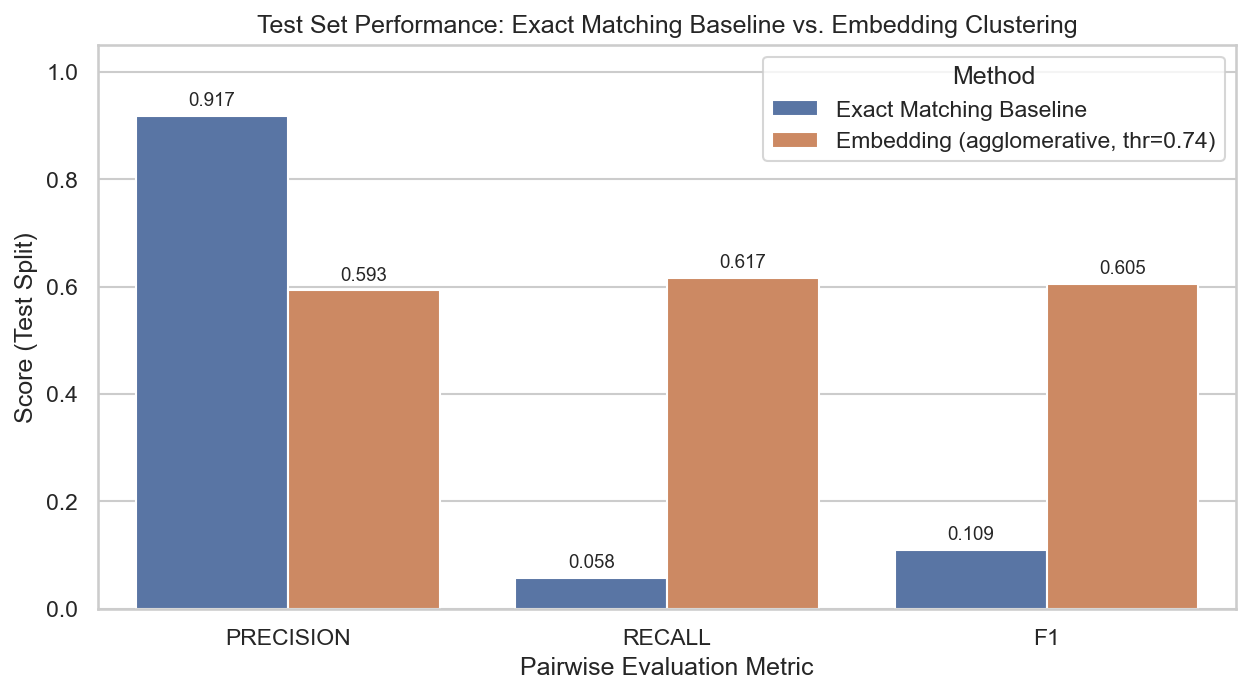

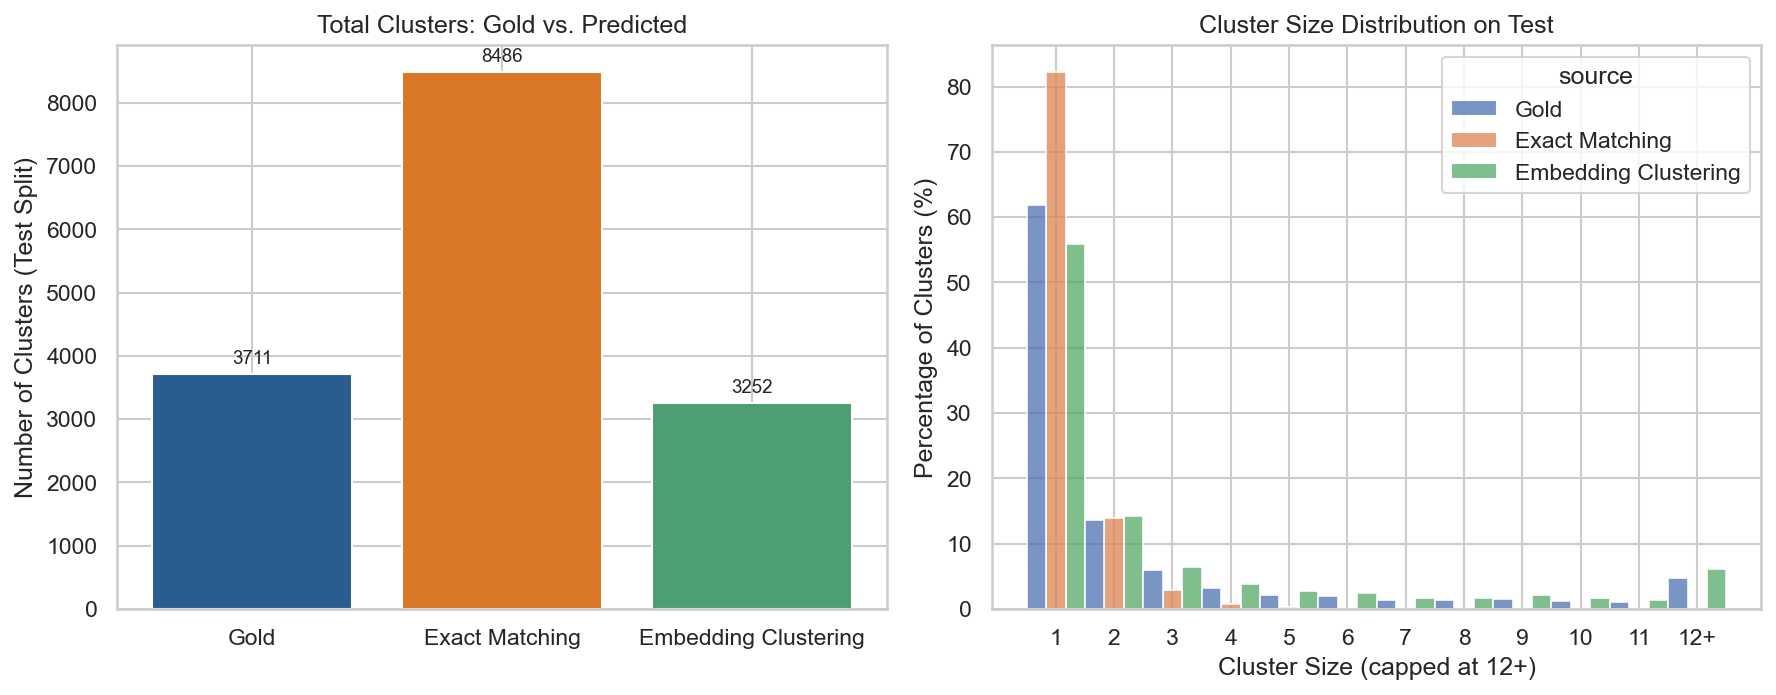

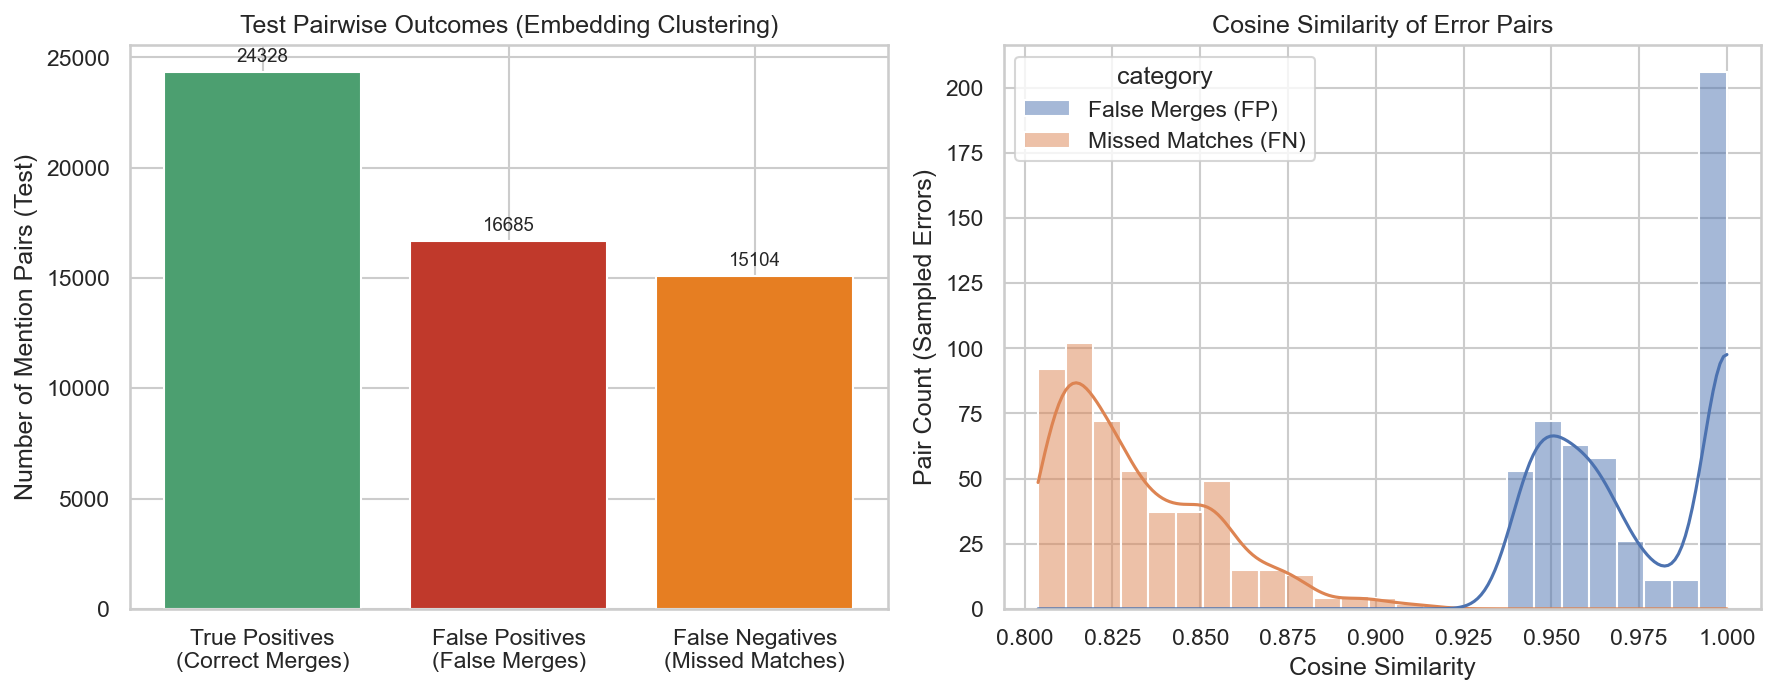

In [5]:
# Display evaluation and error figures
for fig_name in ("05_method_comparison.png", "06_gold_vs_pred_cluster_stats.png", "07_error_category_distribution.png"):
    fig_path = ROOT / cfg["paths"]["figures_dir"] / fig_name
    if fig_path.exists():
        display(Image(filename=str(fig_path)))
